<a href="https://colab.research.google.com/github/alyairawan02/publicdiscussion_analysis/blob/main/PREPROCESSING_Data_Baru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

INI UJI DATA BARU, PROSES KEDUA 26 JULI

In [ ]:
import pandas as pd

# Baca file yang akan diproses
df = pd.read_excel('KataBaru_Uji.xlsx')

# Ubah kolom tertentu ke string (jika diperlukan untuk preprocessing)
kolom_str = ['conversation_id_str', 'id_str', 'user_id_str']
for kolom in kolom_str:
    if kolom in df.columns:
        df[kolom] = df[kolom].astype(str)
    else:
        print(f'Kolom "{kolom}" tidak ditemukan di data.')

**CLEANING 2**

In [ ]:
df = df[['created_at', 'full_text']] #buat ambil 3 kolom aja
df.head(15)

,created_at,full_text
0,Sun Jul 27 17:07:10 +0000 2025,Dukung bersama Program Makan Bergizi Gratis. M...
1,Sun Jul 27 15:46:29 +0000 2025,Bersama kita wujudkan Makan Bergizi Gratis unt...
2,Sun Jul 27 15:46:27 +0000 2025,Makan Bergizi Gratis solusi untuk anak-anak In...
3,Sun Jul 27 15:46:27 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...
4,Sun Jul 27 15:46:26 +0000 2025,Makan Bergizi Gratis investasi untuk masa depa...
5,Sun Jul 27 15:46:25 +0000 2025,Anak-anak Indonesia berhak mendapatkan Makan B...
6,Sun Jul 27 15:46:23 +0000 2025,Dukung Program Makan Bergizi Gratis! Masa depa...
7,Sun Jul 27 15:26:40 +0000 2025,Program Makan Bergizi Gratis membentuk SDM yan...
8,Sun Jul 27 15:25:38 +0000 2025,MBG jadikan anak sekolah perut kenyang otak te...
9,Sun Jul 27 15:11:19 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   created_at  212 non-null    object
 1   full_text   212 non-null    object
dtypes: object(2)
memory usage: 3.4+ KB


In [ ]:
df.drop_duplicates(subset = 'full_text', keep = 'first', inplace = True)
df.info() #hapus data duplikat

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212 entries, 0 to 211
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   created_at  212 non-null    object
 1   full_text   212 non-null    object
dtypes: object(2)
memory usage: 3.4+ KB


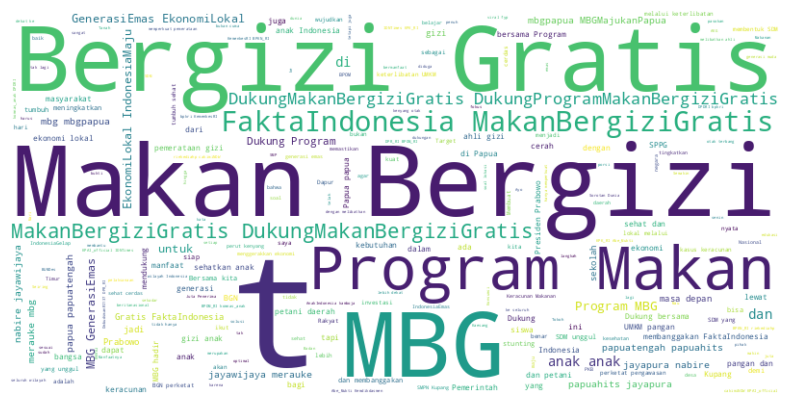

In [ ]:
#cek wordcloud nya
import pandas as pd
import numpy as np
from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt

df['full_text'] = df['full_text'].fillna('')

text = ' '.join(df['full_text'].astype(str).tolist())

stopwords = set(STOPWORDS)
stopwords.update(['https', 'co', 'RT', '...', 'amp'])

wc = WordCloud(stopwords=stopwords, background_color='white', max_words=500, width=800, height=400)
wc.generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()


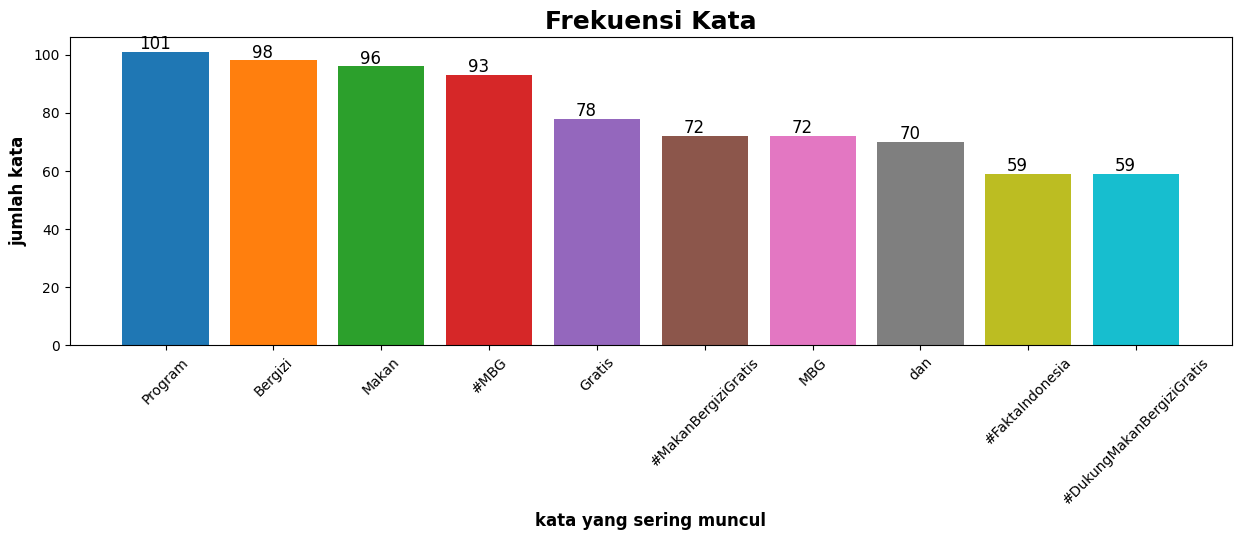

In [ ]:
#untuk mengetahui frekuensi kata
import matplotlib.pyplot as plt
from collections import Counter

text = " ".join(df['full_text'])

tokens = text.split()
words_counts = Counter(tokens)

top_words = words_counts.most_common(10)
word, count = zip(*top_words)
colors = plt.cm.tab10(range(len(word)))

plt.figure(figsize=(15, 4))
bars = plt.bar(word, count, color=colors)
plt.xlabel("kata yang sering muncul", fontsize=12, fontweight='bold')
plt.ylabel("jumlah kata", fontsize=12, fontweight='bold')
plt.title("Frekuensi Kata", fontsize=18, fontweight='bold')
plt.xticks(rotation=45)

for bar, num in zip(bars, count):
    plt.text(bar.get_x() + bar.get_width() / 2 - 0.1, num + 1, str(num), fontsize=12, color='black', ha='center')

plt.show()


**CLEANING 2**

In [ ]:
import re
import string
import nltk

# menghapus emoji
def remove_emoji(tweet):
    if tweet is not None and isinstance(tweet, str):
        emoji_pattern = re.compile(
            "["
            u"\U0001F600-\U0001F64F"  # emoticons
            u"\U0001F300-\U0001F5FF"  # symbols & pictographs
            u"\U0001F680-\U0001F6FF"  # transport & map symbols
            u"\U0001F700-\U0001F77F"  # alchemical symbols
            u"\U0001F780-\U0001F7FF"  # Geometric Shapes Extended
            u"\U0001F800-\U0001F8FF"  # Supplemental Arrows-C
            u"\U0001F900-\U0001F9FF"  # Supplemental Symbols and Pictographs
            u"\U0001FA00-\U0001FA6F"  # Chess Symbols
            u"\U0001FA70-\U0001FAFF"  # Symbols and Pictographs Extended-A
            u"\U0001F004-\U0001F0CF"  # Additional emoticons
            u"\U0001F1E0-\U0001F1FF"  # flags
            "]+",
            flags=re.UNICODE
        )
        return emoji_pattern.sub(r'', tweet)
    else:
        return tweet

# menghapus url
def remove_url(text):
    return re.sub(r'http\S+|www.\S+', '', text)

# menghapus hashtag
def remove_hashtag(text):
    return re.sub(r'#\w+', '', text)

# menghapus simbol
def remove_symbols(tweet):
    if tweet is not None and isinstance(tweet, str):
        tweet = re.sub(r'[^a-zA-Z0-9\s]', '', tweet)
    return tweet

# menghapus angka
def remove_numbers(tweet):
    if tweet is not None and isinstance(tweet, str):
        tweet = re.sub(r'\d', '', tweet)
    return tweet

# menghapus username
def remove_username(text):
    return re.sub(r'@[^\s]+', '', text)

# menghapus ekspresi tertawa
def remove_laughing(text):
    return re.sub(r'\b(?:wkwk|wk|kwkwk|haha|hehe|hihi|huha|lol|lmao)+\b', '', text, flags=re.IGNORECASE)

# menangani negasi
def handle_negation(text):
    if text is not None and isinstance(text, str):
        pos_words = ['senang', 'bagus', 'baik', 'puas', 'suka', 'cocok', 'indah', 'nyaman', 'lancar', 'cepat']
        for word in pos_words:
            text = re.sub(rf'\b(tidak|nggak|kurang)\s+{word}\b', f'tidak_{word}', text)
    return text

# Terapkan cleaning
df['cleaning'] = df['full_text'].apply(lambda x: remove_username(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_emoji(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_url(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_hashtag(x))  # <-- tambahan ini
df['cleaning'] = df['cleaning'].apply(lambda x: remove_symbols(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_numbers(x))
df['cleaning'] = df['cleaning'].apply(lambda x: remove_laughing(x))
df['cleaning'] = df['cleaning'].apply(lambda x: handle_negation(x))

df.head(25)

,created_at,full_text,cleaning
0,Sun Jul 27 17:07:10 +0000 2025,Dukung bersama Program Makan Bergizi Gratis. M...,Dukung bersama Program Makan Bergizi Gratis Me...
1,Sun Jul 27 15:46:29 +0000 2025,Bersama kita wujudkan Makan Bergizi Gratis unt...,Bersama kita wujudkan Makan Bergizi Gratis unt...
2,Sun Jul 27 15:46:27 +0000 2025,Makan Bergizi Gratis solusi untuk anak-anak In...,Makan Bergizi Gratis solusi untuk anakanak Ind...
3,Sun Jul 27 15:46:27 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...
4,Sun Jul 27 15:46:26 +0000 2025,Makan Bergizi Gratis investasi untuk masa depa...,Makan Bergizi Gratis investasi untuk masa depan
5,Sun Jul 27 15:46:25 +0000 2025,Anak-anak Indonesia berhak mendapatkan Makan B...,Anakanak Indonesia berhak mendapatkan Makan Be...
6,Sun Jul 27 15:46:23 +0000 2025,Dukung Program Makan Bergizi Gratis! Masa depa...,Dukung Program Makan Bergizi Gratis Masa depan...
7,Sun Jul 27 15:26:40 +0000 2025,Program Makan Bergizi Gratis membentuk SDM yan...,Program Makan Bergizi Gratis membentuk SDM yan...
8,Sun Jul 27 15:25:38 +0000 2025,MBG jadikan anak sekolah perut kenyang otak te...,MBG jadikan anak sekolah perut kenyang otak te...
9,Sun Jul 27 15:11:19 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...


**TEXT FOLDING**

In [ ]:
def case_folding(text):
  if isinstance(text, str):
    lowercase_text = text.lower() #menyeragamkan kata dengan huruf kecil semua
    return lowercase_text
  else:
    return text

df['case_folding'] = df['cleaning'].apply(case_folding)
df.head(25)

,created_at,full_text,cleaning,case_folding
0,Sun Jul 27 17:07:10 +0000 2025,Dukung bersama Program Makan Bergizi Gratis. M...,Dukung bersama Program Makan Bergizi Gratis Me...,dukung bersama program makan bergizi gratis me...
1,Sun Jul 27 15:46:29 +0000 2025,Bersama kita wujudkan Makan Bergizi Gratis unt...,Bersama kita wujudkan Makan Bergizi Gratis unt...,bersama kita wujudkan makan bergizi gratis unt...
2,Sun Jul 27 15:46:27 +0000 2025,Makan Bergizi Gratis solusi untuk anak-anak In...,Makan Bergizi Gratis solusi untuk anakanak Ind...,makan bergizi gratis solusi untuk anakanak ind...
3,Sun Jul 27 15:46:27 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...
4,Sun Jul 27 15:46:26 +0000 2025,Makan Bergizi Gratis investasi untuk masa depa...,Makan Bergizi Gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan
5,Sun Jul 27 15:46:25 +0000 2025,Anak-anak Indonesia berhak mendapatkan Makan B...,Anakanak Indonesia berhak mendapatkan Makan Be...,anakanak indonesia berhak mendapatkan makan be...
6,Sun Jul 27 15:46:23 +0000 2025,Dukung Program Makan Bergizi Gratis! Masa depa...,Dukung Program Makan Bergizi Gratis Masa depan...,dukung program makan bergizi gratis masa depan...
7,Sun Jul 27 15:26:40 +0000 2025,Program Makan Bergizi Gratis membentuk SDM yan...,Program Makan Bergizi Gratis membentuk SDM yan...,program makan bergizi gratis membentuk sdm yan...
8,Sun Jul 27 15:25:38 +0000 2025,MBG jadikan anak sekolah perut kenyang otak te...,MBG jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...
9,Sun Jul 27 15:11:19 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...


**NORMALISASI KATA**

In [ ]:
import pandas as pd
import requests
from io import BytesIO

# Fungsi penggantian kata tidak baku
def replace_taboo_words(text, kamus_tidak_baku):
    if isinstance(text, str):
        words = text.split()
        replaced_words = []
        kalimat_baku = []
        kata_diganti = []
        kata_tidak_baku_hash = []

        for word in words:
            if word in kamus_tidak_baku:
                baku_word = kamus_tidak_baku[word]
                if isinstance(baku_word, str) and all(char.isalpha() for char in baku_word):
                    replaced_words.append(baku_word)
                    kalimat_baku.append(baku_word)
                    kata_diganti.append(word)
                    kata_tidak_baku_hash.append(hash(word))
            else:
                replaced_words.append(word)  # kata tidak ada di kamus, tetap dipakai

        replaced_text = ' '.join(replaced_words)
    else:
        replaced_text = ''
        kalimat_baku = []
        kata_diganti = []
        kata_tidak_baku_hash = []

    return replaced_text, kalimat_baku, kata_diganti, kata_tidak_baku_hash

# Contoh ambil subset data (pastikan df sudah ada sebelumnya)
data = pd.DataFrame(df[['created_at','full_text', 'cleaning', 'case_folding']])
data.head(5)


,created_at,full_text,cleaning,case_folding
0,Sun Jul 27 17:07:10 +0000 2025,Dukung bersama Program Makan Bergizi Gratis. M...,Dukung bersama Program Makan Bergizi Gratis Me...,dukung bersama program makan bergizi gratis me...
1,Sun Jul 27 15:46:29 +0000 2025,Bersama kita wujudkan Makan Bergizi Gratis unt...,Bersama kita wujudkan Makan Bergizi Gratis unt...,bersama kita wujudkan makan bergizi gratis unt...
2,Sun Jul 27 15:46:27 +0000 2025,Makan Bergizi Gratis solusi untuk anak-anak In...,Makan Bergizi Gratis solusi untuk anakanak Ind...,makan bergizi gratis solusi untuk anakanak ind...
3,Sun Jul 27 15:46:27 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...
4,Sun Jul 27 15:46:26 +0000 2025,Makan Bergizi Gratis investasi untuk masa depa...,Makan Bergizi Gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan


In [ ]:
import pandas as pd

# Baca file Excel dari path lokal
kamus_data = pd.read_excel('kamuskatabaku.xlsx')

# Buat dictionary dari kamus
kamus_tidak_baku = dict(zip(kamus_data['tidak_baku'], kamus_data['kata_baku']))

In [ ]:
#penerapan fungsi normalisasi

data[['normalisasi', 'Kata_Baku', 'Kata_Tidak_Baku', 'Kata_Tidak_Baku_Hash']] = data['case_folding'].apply(lambda x: pd.Series(replace_taboo_words(x, kamus_tidak_baku)))

df = pd.DataFrame(data[['created_at','full_text', 'cleaning', 'case_folding', 'normalisasi']])

df.head(15)

,created_at,full_text,cleaning,case_folding,normalisasi
0,Sun Jul 27 17:07:10 +0000 2025,Dukung bersama Program Makan Bergizi Gratis. M...,Dukung bersama Program Makan Bergizi Gratis Me...,dukung bersama program makan bergizi gratis me...,dukung bersama program makan bergizi gratis me...
1,Sun Jul 27 15:46:29 +0000 2025,Bersama kita wujudkan Makan Bergizi Gratis unt...,Bersama kita wujudkan Makan Bergizi Gratis unt...,bersama kita wujudkan makan bergizi gratis unt...,bersama kita wujudkan makan bergizi gratis unt...
2,Sun Jul 27 15:46:27 +0000 2025,Makan Bergizi Gratis solusi untuk anak-anak In...,Makan Bergizi Gratis solusi untuk anakanak Ind...,makan bergizi gratis solusi untuk anakanak ind...,makan bergizi gratis solusi untuk anakanak ind...
3,Sun Jul 27 15:46:27 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...,bersama kita dukung program makan bergizi gratis
4,Sun Jul 27 15:46:26 +0000 2025,Makan Bergizi Gratis investasi untuk masa depa...,Makan Bergizi Gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan
5,Sun Jul 27 15:46:25 +0000 2025,Anak-anak Indonesia berhak mendapatkan Makan B...,Anakanak Indonesia berhak mendapatkan Makan Be...,anakanak indonesia berhak mendapatkan makan be...,anakanak indonesia berhak mendapatkan makan be...
6,Sun Jul 27 15:46:23 +0000 2025,Dukung Program Makan Bergizi Gratis! Masa depa...,Dukung Program Makan Bergizi Gratis Masa depan...,dukung program makan bergizi gratis masa depan...,dukung program makan bergizi gratis masa depan...
7,Sun Jul 27 15:26:40 +0000 2025,Program Makan Bergizi Gratis membentuk SDM yan...,Program Makan Bergizi Gratis membentuk SDM yan...,program makan bergizi gratis membentuk sdm yan...,program makan bergizi gratis membentuk sdm yan...
8,Sun Jul 27 15:25:38 +0000 2025,MBG jadikan anak sekolah perut kenyang otak te...,MBG jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...
9,Sun Jul 27 15:11:19 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...,bersama kita dukung program makan bergizi gratis


**TOKENIZATION**

In [ ]:
def tokenize(text):
  tokens = text.split()
  return tokens

df['tokenize'] = df['normalisasi'].apply(tokenize)

df.head(15)

,created_at,full_text,cleaning,case_folding,normalisasi,tokenize
0,Sun Jul 27 17:07:10 +0000 2025,Dukung bersama Program Makan Bergizi Gratis. M...,Dukung bersama Program Makan Bergizi Gratis Me...,dukung bersama program makan bergizi gratis me...,dukung bersama program makan bergizi gratis me...,"[dukung, bersama, program, makan, bergizi, gra..."
1,Sun Jul 27 15:46:29 +0000 2025,Bersama kita wujudkan Makan Bergizi Gratis unt...,Bersama kita wujudkan Makan Bergizi Gratis unt...,bersama kita wujudkan makan bergizi gratis unt...,bersama kita wujudkan makan bergizi gratis unt...,"[bersama, kita, wujudkan, makan, bergizi, grat..."
2,Sun Jul 27 15:46:27 +0000 2025,Makan Bergizi Gratis solusi untuk anak-anak In...,Makan Bergizi Gratis solusi untuk anakanak Ind...,makan bergizi gratis solusi untuk anakanak ind...,makan bergizi gratis solusi untuk anakanak ind...,"[makan, bergizi, gratis, solusi, untuk, anakan..."
3,Sun Jul 27 15:46:27 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...,bersama kita dukung program makan bergizi gratis,"[bersama, kita, dukung, program, makan, bergiz..."
4,Sun Jul 27 15:46:26 +0000 2025,Makan Bergizi Gratis investasi untuk masa depa...,Makan Bergizi Gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan,"[makan, bergizi, gratis, investasi, untuk, mas..."
5,Sun Jul 27 15:46:25 +0000 2025,Anak-anak Indonesia berhak mendapatkan Makan B...,Anakanak Indonesia berhak mendapatkan Makan Be...,anakanak indonesia berhak mendapatkan makan be...,anakanak indonesia berhak mendapatkan makan be...,"[anakanak, indonesia, berhak, mendapatkan, mak..."
6,Sun Jul 27 15:46:23 +0000 2025,Dukung Program Makan Bergizi Gratis! Masa depa...,Dukung Program Makan Bergizi Gratis Masa depan...,dukung program makan bergizi gratis masa depan...,dukung program makan bergizi gratis masa depan...,"[dukung, program, makan, bergizi, gratis, masa..."
7,Sun Jul 27 15:26:40 +0000 2025,Program Makan Bergizi Gratis membentuk SDM yan...,Program Makan Bergizi Gratis membentuk SDM yan...,program makan bergizi gratis membentuk sdm yan...,program makan bergizi gratis membentuk sdm yan...,"[program, makan, bergizi, gratis, membentuk, s..."
8,Sun Jul 27 15:25:38 +0000 2025,MBG jadikan anak sekolah perut kenyang otak te...,MBG jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...,"[mbg, jadikan, anak, sekolah, perut, kenyang, ..."
9,Sun Jul 27 15:11:19 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...,bersama kita dukung program makan bergizi gratis,"[bersama, kita, dukung, program, makan, bergiz..."


**STOPWORLD REMOVAL**

In [ ]:
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = stopwords.words('indonesian')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
negasi = ['tidak', 'nggak', 'bukan', 'kurang', 'belum']
stop_words = [word for word in stopwords.words('indonesian') if word not in negasi]

In [ ]:
def remove_stopwords(text):
  return[word for word in text if word not in stop_words]

df['stopword removal'] = df['tokenize'].apply(lambda x: remove_stopwords(x))

df.head(15)

,created_at,full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal
0,Sun Jul 27 17:07:10 +0000 2025,Dukung bersama Program Makan Bergizi Gratis. M...,Dukung bersama Program Makan Bergizi Gratis Me...,dukung bersama program makan bergizi gratis me...,dukung bersama program makan bergizi gratis me...,"[dukung, bersama, program, makan, bergizi, gra...","[dukung, program, makan, bergizi, gratis, anak..."
1,Sun Jul 27 15:46:29 +0000 2025,Bersama kita wujudkan Makan Bergizi Gratis unt...,Bersama kita wujudkan Makan Bergizi Gratis unt...,bersama kita wujudkan makan bergizi gratis unt...,bersama kita wujudkan makan bergizi gratis unt...,"[bersama, kita, wujudkan, makan, bergizi, grat...","[wujudkan, makan, bergizi, gratis, anakanak, i..."
2,Sun Jul 27 15:46:27 +0000 2025,Makan Bergizi Gratis solusi untuk anak-anak In...,Makan Bergizi Gratis solusi untuk anakanak Ind...,makan bergizi gratis solusi untuk anakanak ind...,makan bergizi gratis solusi untuk anakanak ind...,"[makan, bergizi, gratis, solusi, untuk, anakan...","[makan, bergizi, gratis, solusi, anakanak, ind..."
3,Sun Jul 27 15:46:27 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...,bersama kita dukung program makan bergizi gratis,"[bersama, kita, dukung, program, makan, bergiz...","[dukung, program, makan, bergizi, gratis]"
4,Sun Jul 27 15:46:26 +0000 2025,Makan Bergizi Gratis investasi untuk masa depa...,Makan Bergizi Gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan,"[makan, bergizi, gratis, investasi, untuk, mas...","[makan, bergizi, gratis, investasi]"
5,Sun Jul 27 15:46:25 +0000 2025,Anak-anak Indonesia berhak mendapatkan Makan B...,Anakanak Indonesia berhak mendapatkan Makan Be...,anakanak indonesia berhak mendapatkan makan be...,anakanak indonesia berhak mendapatkan makan be...,"[anakanak, indonesia, berhak, mendapatkan, mak...","[anakanak, indonesia, berhak, makan, bergizi, ..."
6,Sun Jul 27 15:46:23 +0000 2025,Dukung Program Makan Bergizi Gratis! Masa depa...,Dukung Program Makan Bergizi Gratis Masa depan...,dukung program makan bergizi gratis masa depan...,dukung program makan bergizi gratis masa depan...,"[dukung, program, makan, bergizi, gratis, masa...","[dukung, program, makan, bergizi, gratis, anak..."
7,Sun Jul 27 15:26:40 +0000 2025,Program Makan Bergizi Gratis membentuk SDM yan...,Program Makan Bergizi Gratis membentuk SDM yan...,program makan bergizi gratis membentuk sdm yan...,program makan bergizi gratis membentuk sdm yan...,"[program, makan, bergizi, gratis, membentuk, s...","[program, makan, bergizi, gratis, membentuk, s..."
8,Sun Jul 27 15:25:38 +0000 2025,MBG jadikan anak sekolah perut kenyang otak te...,MBG jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...,"[mbg, jadikan, anak, sekolah, perut, kenyang, ...","[mbg, jadikan, anak, sekolah, perut, kenyang, ..."
9,Sun Jul 27 15:11:19 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...,bersama kita dukung program makan bergizi gratis,"[bersama, kita, dukung, program, makan, bergiz...","[dukung, program, makan, bergizi, gratis]"


**STEMMING DATA**

In [ ]:
!pip install Sastrawi

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from nltk.stem import PorterStemmer
from nltk.stem.snowball import SnowballStemmer

In [ ]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

def stem_text(text):
  return [stemmer.stem(word) for word in text]

df['stemming_data'] = df['stopword removal'].apply(lambda x: ' '.join(stem_text(x)))
df.to_excel('hasil_preprocessing_ujibaru.xlsx', index=False)
df.head(25)

,created_at,full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,stemming_data
0,Sun Jul 27 17:07:10 +0000 2025,Dukung bersama Program Makan Bergizi Gratis. M...,Dukung bersama Program Makan Bergizi Gratis Me...,dukung bersama program makan bergizi gratis me...,dukung bersama program makan bergizi gratis me...,"[dukung, bersama, program, makan, bergizi, gra...","[dukung, program, makan, bergizi, gratis, anak...",dukung program makan gizi gratis anakanak cera...
1,Sun Jul 27 15:46:29 +0000 2025,Bersama kita wujudkan Makan Bergizi Gratis unt...,Bersama kita wujudkan Makan Bergizi Gratis unt...,bersama kita wujudkan makan bergizi gratis unt...,bersama kita wujudkan makan bergizi gratis unt...,"[bersama, kita, wujudkan, makan, bergizi, grat...","[wujudkan, makan, bergizi, gratis, anakanak, i...",wujud makan gizi gratis anakanak indonesia
2,Sun Jul 27 15:46:27 +0000 2025,Makan Bergizi Gratis solusi untuk anak-anak In...,Makan Bergizi Gratis solusi untuk anakanak Ind...,makan bergizi gratis solusi untuk anakanak ind...,makan bergizi gratis solusi untuk anakanak ind...,"[makan, bergizi, gratis, solusi, untuk, anakan...","[makan, bergizi, gratis, solusi, anakanak, ind...",makan gizi gratis solusi anakanak indonesia
3,Sun Jul 27 15:46:27 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...,bersama kita dukung program makan bergizi gratis,"[bersama, kita, dukung, program, makan, bergiz...","[dukung, program, makan, bergizi, gratis]",dukung program makan gizi gratis
4,Sun Jul 27 15:46:26 +0000 2025,Makan Bergizi Gratis investasi untuk masa depa...,Makan Bergizi Gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan,"[makan, bergizi, gratis, investasi, untuk, mas...","[makan, bergizi, gratis, investasi]",makan gizi gratis investasi
5,Sun Jul 27 15:46:25 +0000 2025,Anak-anak Indonesia berhak mendapatkan Makan B...,Anakanak Indonesia berhak mendapatkan Makan Be...,anakanak indonesia berhak mendapatkan makan be...,anakanak indonesia berhak mendapatkan makan be...,"[anakanak, indonesia, berhak, mendapatkan, mak...","[anakanak, indonesia, berhak, makan, bergizi, ...",anakanak indonesia hak makan gizi gratis
6,Sun Jul 27 15:46:23 +0000 2025,Dukung Program Makan Bergizi Gratis! Masa depa...,Dukung Program Makan Bergizi Gratis Masa depan...,dukung program makan bergizi gratis masa depan...,dukung program makan bergizi gratis masa depan...,"[dukung, program, makan, bergizi, gratis, masa...","[dukung, program, makan, bergizi, gratis, anak...",dukung program makan gizi gratis anakanak cerah
7,Sun Jul 27 15:26:40 +0000 2025,Program Makan Bergizi Gratis membentuk SDM yan...,Program Makan Bergizi Gratis membentuk SDM yan...,program makan bergizi gratis membentuk sdm yan...,program makan bergizi gratis membentuk sdm yan...,"[program, makan, bergizi, gratis, membentuk, s...","[program, makan, bergizi, gratis, membentuk, s...",program makan gizi gratis bentuk sdm unggul ba...
8,Sun Jul 27 15:25:38 +0000 2025,MBG jadikan anak sekolah perut kenyang otak te...,MBG jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...,"[mbg, jadikan, anak, sekolah, perut, kenyang, ...","[mbg, jadikan, anak, sekolah, perut, kenyang, ...",mbg jadi anak sekolah perut kenyang otak terbang
9,Sun Jul 27 15:11:19 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...,bersama kita dukung program makan bergizi gratis,"[bersama, kita, dukung, program, makan, bergiz...","[dukung, program, makan, bergizi, gratis]",dukung program makan gizi gratis


In [ ]:
#cek kolom

print(data.columns)

Index(['created_at', 'full_text', 'cleaning', 'case_folding', 'normalisasi',
       'Kata_Baku', 'Kata_Tidak_Baku', 'Kata_Tidak_Baku_Hash'],
      dtype='object')


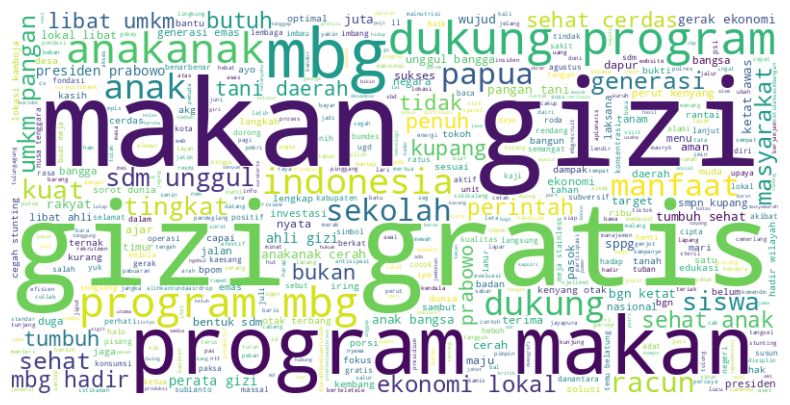

In [ ]:
# Cek WordCloud-nya
import pandas as pd
import numpy as np
from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt

# 1. Baca file Excel langsung
df = pd.read_excel('hasil_preprocessing_ujibaru.xlsx')  # Ganti sesuai nama file kamu

# 2. Ambil dan gabungkan teks dari kolom stemming_data
text = ' '.join(df['stemming_data'].astype(str).tolist())

# 3. Tambahkan stopwords khusus
stopwords = set(STOPWORDS)
stopwords.update(['https', 'co', 'RT', '...', 'amp', 'lu', 'deh', 'fyp', 'ya', 'gue', 'kak'])

# 4. Generate WordCloud
wc = WordCloud(stopwords=stopwords, background_color='white', max_words=500, width=800, height=400)
wc.generate(text)

# 5. Tampilkan
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()


In [ ]:
import pandas as pd

df = pd.read_excel('hasil_preprocessing_ujibaru.xlsx')
print(df.columns.tolist())

['created_at', 'full_text', 'cleaning', 'case_folding', 'normalisasi', 'tokenize', 'stopword removal', 'stemming_data']


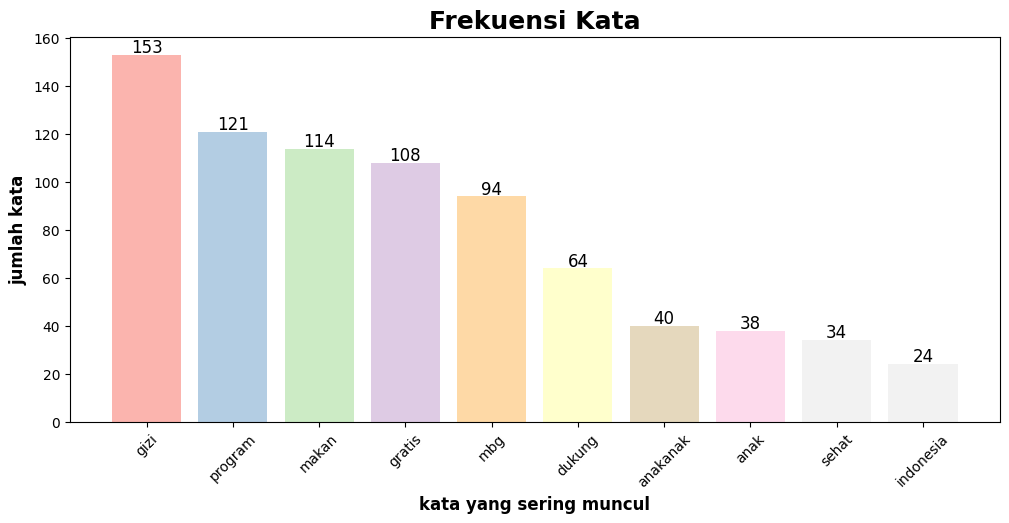

In [ ]:
#frekuensi kata
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import STOPWORDS

text = " ".join(df['stemming_data'].astype(str))

stopwords = set(STOPWORDS)
stopwords.update(['https', 'co', 'RT', '...', 'amp', 'lu', 'deh', 'fyp', 'ya', 'gue', 'kak'])

tokens = [word for word in text.split() if word not in stopwords]
words_counts = Counter(tokens)

top_words = words_counts.most_common(10)
word, count = zip(*top_words)
colors = plt.cm.Pastel1(range(len(word)))

plt.figure(figsize=(12, 5))
bars = plt.bar(word, count, color=colors)
plt.xlabel("kata yang sering muncul", fontsize=12, fontweight='bold')
plt.ylabel("jumlah kata", fontsize=12, fontweight='bold')
plt.title("Frekuensi Kata", fontsize=18, fontweight='bold')
plt.xticks(rotation=45)

for bar, num in zip(bars, count):
    plt.text(bar.get_x() + bar.get_width() / 1.6 - 0.1, num + 1, str(num), fontsize=12, color='black', ha='center')

plt.show()#menampilkan diagram


**INDOBERT**

In [ ]:
!pip install transformers torch

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

# Load model IndoBERT Sentiment Analysis
model_name = "crypter70/IndoBERT-Sentiment-Analysis"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Buat pipeline untuk analisis sentimen
sentiment_pipe = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

Device set to use cpu


In [ ]:
import pandas as pd

# Load file CSV
df = pd.read_excel('hasil_preprocessing_ujibaru.xlsx')

df[['normalisasi']].head()

,normalisasi
0,dukung bersama program makan bergizi gratis me...
1,bersama kita wujudkan makan bergizi gratis unt...
2,makan bergizi gratis solusi untuk anakanak ind...
3,bersama kita dukung program makan bergizi gratis
4,makan bergizi gratis investasi untuk masa depan


In [ ]:
def get_sentiment(text):
    try:
        result = sentiment_pipe(text)[0]
        label = result['label']
        score = result['score']

        # Mapping label IndoBERT
        mapping = {
            'LABEL_0': 'positive',
            'LABEL_1': 'neutral',
            'LABEL_2': 'negative'
        }

        return mapping.get(label, label), score
    except:
        return None, None

In [ ]:
# Membersihkan kolom dari NaN atau baris kosong
df = df[df['normalisasi'].notna()]
df = df[df['normalisasi'].str.strip() != '']
df.loc[:, 'normalisasi'] = df['normalisasi'].astype(str)
df = df.reset_index(drop=True)

# Terapkan label sentimen
df['sent_label'], df['sent_score'] = zip(*df['normalisasi'].apply(get_sentiment))


In [ ]:
import pandas as pd

# Terapkan labeling ke seluruh data
df['sent_label'], df['sent_score'] = zip(*df['normalisasi'].apply(get_sentiment))

# Cek hasil awal
df[['normalisasi', 'sent_label', 'sent_score']]
df.head(30)

,created_at,full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,stemming_data,sent_label,sent_score
0,Sun Jul 27 17:07:10 +0000 2025,Dukung bersama Program Makan Bergizi Gratis. M...,Dukung bersama Program Makan Bergizi Gratis Me...,dukung bersama program makan bergizi gratis me...,dukung bersama program makan bergizi gratis me...,"['dukung', 'bersama', 'program', 'makan', 'ber...","['dukung', 'program', 'makan', 'bergizi', 'gra...",dukung program makan gizi gratis anakanak cera...,POSITIVE,0.999951
1,Sun Jul 27 15:46:29 +0000 2025,Bersama kita wujudkan Makan Bergizi Gratis unt...,Bersama kita wujudkan Makan Bergizi Gratis unt...,bersama kita wujudkan makan bergizi gratis unt...,bersama kita wujudkan makan bergizi gratis unt...,"['bersama', 'kita', 'wujudkan', 'makan', 'berg...","['wujudkan', 'makan', 'bergizi', 'gratis', 'an...",wujud makan gizi gratis anakanak indonesia,POSITIVE,0.989740
2,Sun Jul 27 15:46:27 +0000 2025,Makan Bergizi Gratis solusi untuk anak-anak In...,Makan Bergizi Gratis solusi untuk anakanak Ind...,makan bergizi gratis solusi untuk anakanak ind...,makan bergizi gratis solusi untuk anakanak ind...,"['makan', 'bergizi', 'gratis', 'solusi', 'untu...","['makan', 'bergizi', 'gratis', 'solusi', 'anak...",makan gizi gratis solusi anakanak indonesia,POSITIVE,0.999927
3,Sun Jul 27 15:46:27 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...,bersama kita dukung program makan bergizi gratis,"['bersama', 'kita', 'dukung', 'program', 'maka...","['dukung', 'program', 'makan', 'bergizi', 'gra...",dukung program makan gizi gratis,POSITIVE,0.999875
4,Sun Jul 27 15:46:26 +0000 2025,Makan Bergizi Gratis investasi untuk masa depa...,Makan Bergizi Gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan,makan bergizi gratis investasi untuk masa depan,"['makan', 'bergizi', 'gratis', 'investasi', 'u...","['makan', 'bergizi', 'gratis', 'investasi']",makan gizi gratis investasi,POSITIVE,0.999268
5,Sun Jul 27 15:46:25 +0000 2025,Anak-anak Indonesia berhak mendapatkan Makan B...,Anakanak Indonesia berhak mendapatkan Makan Be...,anakanak indonesia berhak mendapatkan makan be...,anakanak indonesia berhak mendapatkan makan be...,"['anakanak', 'indonesia', 'berhak', 'mendapatk...","['anakanak', 'indonesia', 'berhak', 'makan', '...",anakanak indonesia hak makan gizi gratis,NEUTRAL,0.999836
6,Sun Jul 27 15:46:23 +0000 2025,Dukung Program Makan Bergizi Gratis! Masa depa...,Dukung Program Makan Bergizi Gratis Masa depan...,dukung program makan bergizi gratis masa depan...,dukung program makan bergizi gratis masa depan...,"['dukung', 'program', 'makan', 'bergizi', 'gra...","['dukung', 'program', 'makan', 'bergizi', 'gra...",dukung program makan gizi gratis anakanak cerah,POSITIVE,0.999914
7,Sun Jul 27 15:26:40 +0000 2025,Program Makan Bergizi Gratis membentuk SDM yan...,Program Makan Bergizi Gratis membentuk SDM yan...,program makan bergizi gratis membentuk sdm yan...,program makan bergizi gratis membentuk sdm yan...,"['program', 'makan', 'bergizi', 'gratis', 'mem...","['program', 'makan', 'bergizi', 'gratis', 'mem...",program makan gizi gratis bentuk sdm unggul ba...,POSITIVE,0.999872
8,Sun Jul 27 15:25:38 +0000 2025,MBG jadikan anak sekolah perut kenyang otak te...,MBG jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...,mbg jadikan anak sekolah perut kenyang otak te...,"['mbg', 'jadikan', 'anak', 'sekolah', 'perut',...","['mbg', 'jadikan', 'anak', 'sekolah', 'perut',...",mbg jadi anak sekolah perut kenyang otak terbang,POSITIVE,0.981012
9,Sun Jul 27 15:11:19 +0000 2025,Bersama kita dukung Program Makan Bergizi Grat...,Bersama kita dukung Program Makan Bergizi Grat...,bersama kita dukung program makan bergizi grat...,bersama kita dukung program makan bergizi gratis,"['bersama', 'kita', 'dukung', 'program', 'maka...","['dukung', 'program', 'makan',

In [ ]:
df.to_excel('hasil_labeling_ujidata.xlsx', index=False)

Persentase Sentimen:
sent_label
NEUTRAL     49.06
POSITIVE    43.87
NEGATIVE     7.08
Name: proportion, dtype: float64


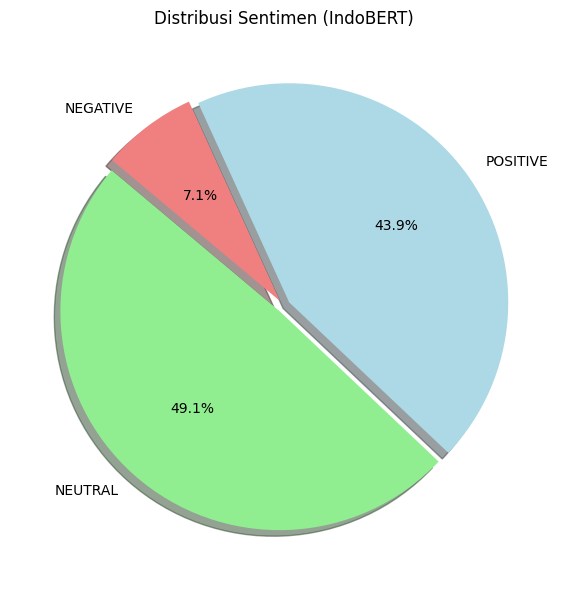

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# hitung persentase masing-masing sentimen
label_counts = df['sent_label'].value_counts(normalize=True) * 100

# ditampilkan dengan angka
print("Persentase Sentimen:")
print(label_counts.round(2))

# visualisasi pie chart
plt.figure(figsize=(6, 6))
colors = ['lightgreen', 'lightblue','lightcoral']  # NEGATIVE, NEUTRAL, POSITIVE
label_counts.plot(kind='pie',
                  autopct='%1.1f%%',
                  colors=colors,
                  startangle=140,
                  shadow=True,
                  explode=(0.03, 0.03, 0.03))

plt.title('Distribusi Sentimen (IndoBERT)')
plt.ylabel('')  # hilangkan label y
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load data
df = pd.read_excel('hasil_labeling_3.xlsx')

# Encode label (pastikan kolom label bernama 'sent_label')
label_encoder = LabelEncoder()
df['encoded_label'] = label_encoder.fit_transform(df['sent_label'])


In [ ]:
print(tokenizer.vocab_size)  # ✅ jumlah token dalam vocab IndoBERT

30521


In [ ]:
df['normalisasi'] = df['normalisasi'].fillna('').astype(str)

In [ ]:
# Tokenisasi teks
tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
tokenizer.fit_on_texts(df['normalisasi'])

sequences = tokenizer.texts_to_sequences(df['normalisasi'])

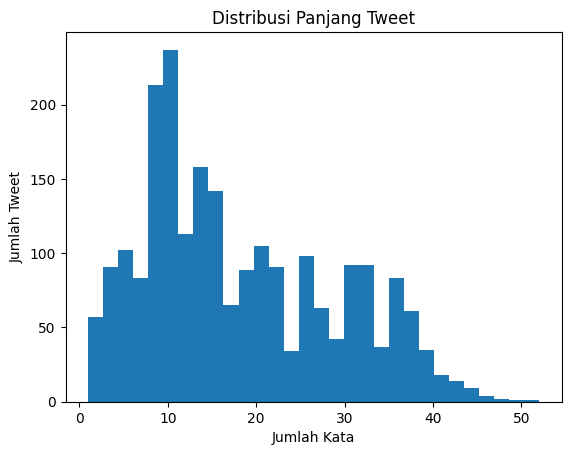

In [ ]:
import matplotlib.pyplot as plt

# Hitung panjang setiap tweet
tweet_lengths = [len(tweet.split()) for tweet in df['normalisasi']]

# Visualisasikan distribusinya
plt.hist(tweet_lengths, bins=30)
plt.title('Distribusi Panjang Tweet')
plt.xlabel('Jumlah Kata')
plt.ylabel('Jumlah Tweet')
plt.show()

In [ ]:
# Padding
max_len = 100  # distribusi panjang teks
padded_sequences = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')

In [ ]:
from tensorflow.keras.utils import to_categorical

# One-hot encoding untuk label
onehot_labels = to_categorical(df['encoded_label'], num_classes=3)

# 0 → [1. 0. 0.]
# 1 → [0. 1. 0.]
# 2 → [0. 0. 1.]


In [ ]:
df.head(5)

,created_at,username,full_text,cleaning,case_folding,normalisasi,tokenize,stopword removal,stemming_data,sent_label,sent_score,encoded_label
0,Fri Dec 27 22:21:19 +0000 2024,PanitiaMbg,@opposite6892 Orang gila 300 T ruginya,Orang gila T ruginya,orang gila t ruginya,orang gila t ruginya,"['orang', 'gila', 't', 'ruginya']","['orang', 'gila', 't', 'ruginya']",orang gila t rugi,NEGATIVE,0.999951,0
1,Fri Dec 27 22:14:23 +0000 2024,PanitiaMbg,@zakariamlk nanti juga kalau mau minjem lagi p...,nanti juga kalau mau minjem lagi paling diunb...,nanti juga kalau mau minjem lagi paling diunb...,nanti juga kalau mau minjem lagi paling diunblock,"['nanti', 'juga', 'kalau', 'mau', 'minjem', 'l...","['minjem', 'diunblock']",minjem diunblock,NEUTRAL,0.999511,1
2,Fri Dec 27 17:49:09 +0000 2024,PanitiaMbg,@nonerahm @ruangtaktik @bliblidotcom nahini le...,nahini lebih manuk akal,nahini lebih manuk akal,nahini lebih masuk akal,"['nahini', 'lebih', 'masuk', 'akal']","['nahini', 'masuk', 'akal']",nahini masuk akal,POSITIVE,0.999953,2
3,Fri Dec 27 15:21:39 +0000 2024,ZoneVenomWar,Warga x yang ga napak tanah bingung lihat ini....,Warga x yang ga napak tanah bingung lihat ini ...,warga x yang ga napak tanah bingung lihat ini ...,warga kali yang tidak napak tanah bingung liha...,"['warga', 'kali', 'yang', 'tidak', 'napak', 't...","['warga', 'kali', 'tidak', 'napak', 'tanah', '...",warga kali tidak napak tanah bingung lihat ber...,NEGATIVE,0.999727,0
4,Fri Dec 27 15:04:34 +0000 2024,aanacessary,hidup lagi capek capeknya jaket vintage ku dic...,hidup lagi capek capeknya jaket vintage ku dic...,hidup lagi capek capeknya jaket vintage ku dic...,hidup lagi capek capeknya jaket vintage ku dic...,"['hidup', 'lagi', 'capek', 'capeknya', 'jaket'...","['hidup', 'capek', 'capeknya', 'jaket', 'vinta...",hidup capek capek jaket vintage ku colong oran...,NEGATIVE,0.999936,0


In [ ]:
#split data (test set & training set)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    padded_sequences, onehot_labels,
    test_size=0.2,
    random_state=42
)

In [ ]:
#visualisasi split data
print("Shape X_train:", X_train.shape)
print("Shape X_test:", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test:", y_test.shape)

Shape X_train: (1785, 100)
Shape X_test: (447, 100)
Shape y_train: (1785, 3)
Shape y_test: (447, 3)


In [ ]:
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 1785
Jumlah data testing: 447


In [ ]:
#SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE
from tensorflow.keras.utils import to_categorical
import numpy as np

# 1. Ubah label dari one-hot ke label integer dulu
y_train_labels = np.argmax(y_train, axis=1)

# 2. Terapkan SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled_labels = smote.fit_resample(X_train, y_train_labels)

# 3. Kembalikan hasil SMOTE ke one-hot encoding
y_train_resampled = to_categorical(y_train_resampled_labels, num_classes=3)

# 4. Cek hasil
print("Shape X_train_resampled:", X_train_resampled.shape)
print("Shape y_train_resampled:", y_train_resampled.shape)

Shape X_train_resampled: (2463, 100)
Shape y_train_resampled: (2463, 3)


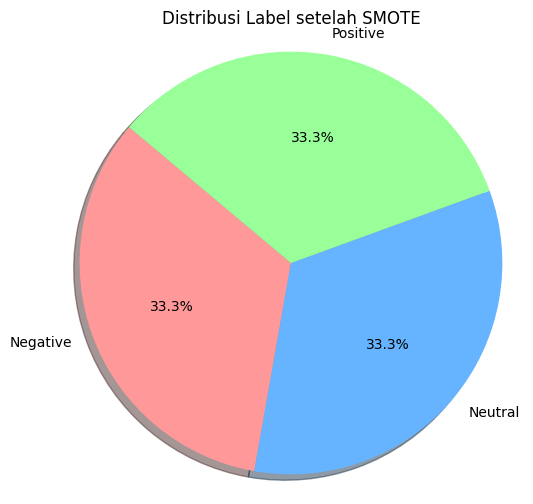

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ambil label hasil SMOTE (dari one-hot ke label)
resampled_labels = np.argmax(y_train_resampled, axis=1)

# Hitung jumlah per label
unique, counts = np.unique(resampled_labels, return_counts=True)
label_names = ['Negative', 'Neutral', 'Positive']
colors = ['#ff9999', '#66b3ff', '#99ff99']

# Pie chart
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=label_names, autopct='%1.1f%%', colors=colors, startangle=140, shadow=True)
plt.title('Distribusi Label setelah SMOTE')
plt.axis('equal')
plt.show()